In [1]:
# Setup: paths, metadata, splits
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive
from PIL import Image
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

SEED = 42
IMG_SIZE = 224
BATCH = 32
RESULTS_NAME = "HAM10000_results_final"
AUTOTUNE = tf.data.AUTOTUNE
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive")
IMG_DIR = Path("/content/skin_cancer_images")
RESULTS_DIR = DATA_DIR / RESULTS_NAME
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")
expected = set(meta["image_id"].astype(str))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
def image_map():
    return {p.stem: str(p) for p in IMG_DIR.rglob("*.jpg")}


paths = image_map()
if not expected.issubset(paths.keys()):
    for name in ["HAM10000_images_part_1.zip", "HAM10000_images_part_2.zip"]:
        print("Extracting:", name)
        with zipfile.ZipFile(DATA_DIR / name) as z:
            z.extractall(IMG_DIR)
    paths = image_map()
meta["path"] = meta["image_id"].map(paths)
assert meta["path"].notna().all(), "Some images are missing"

class_names = sorted(meta["dx"].unique().tolist())
MEL = class_names.index("mel")
meta["label"] = pd.Categorical(meta["dx"], categories=class_names).codes.astype("int32")

frames = {}
for name in ["train", "val", "test"]:
    s = pd.read_csv(RESULTS_DIR / f"{name}_split.csv")
    f = s[["image_id"]].merge(meta, on="image_id", how="left")
    assert (f["label"].to_numpy() == s["label"].to_numpy()).all(), f"Label mismatch in {name}"
    frames[name] = f
    print(name, len(f), "images")

SAVE = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
FULL = {"akiec": "Actinic keratoses", "bcc": "Basal cell carcinoma", "bkl": "Benign keratosis",
        "df": "Dermatofibroma", "mel": "Melanoma", "nv": "Melanocytic nevi", "vasc": "Vascular lesions"}
COL = {"CNN": "#8d99ae", "EfficientNetB0": "#2a6f97"}

train 6981 images
val 1020 images
test 2014 images


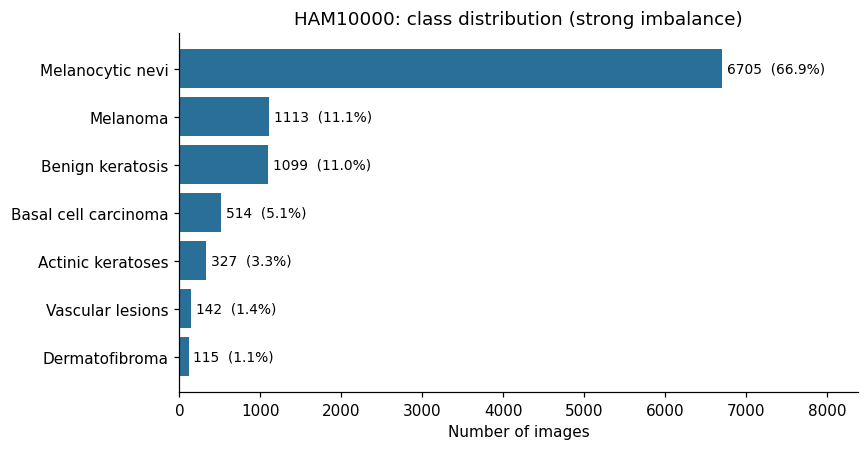

In [3]:
# Data figures
# D1. Class distribution
counts = meta["dx"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.2))
names = [FULL[c] for c in counts.index][::-1]
vals = counts.to_numpy()[::-1]
ax.barh(names, vals, color="#2a6f97")
for i, v in enumerate(vals):
    ax.text(v + 60, i, f"{v}  ({v / len(meta):.1%})", va="center", fontsize=9)
ax.set_xlim(0, vals.max() * 1.25)
ax.set_xlabel("Number of images")
ax.set_title("HAM10000: class distribution (strong imbalance)")
plt.tight_layout(); SAVE(fig, "data_01_class_distribution"); plt.show()

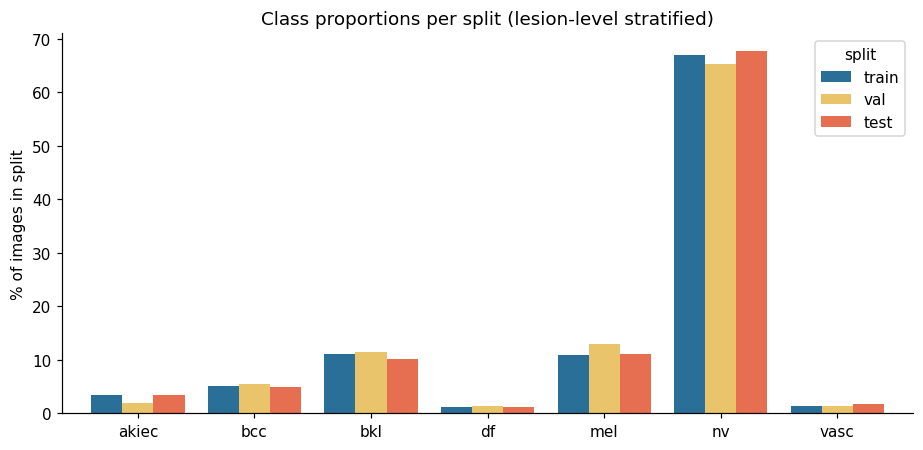

In [4]:
# D2. Class proportions per split (shows that the stratified split worked)
prop = pd.DataFrame({n: f["dx"].value_counts(normalize=True) for n, f in frames.items()}).reindex(class_names) * 100
fig, ax = plt.subplots(figsize=(8.5, 4.2))
prop.plot(kind="bar", ax=ax, width=0.8, color=["#2a6f97", "#e9c46a", "#e76f51"])
ax.set_ylabel("% of images in split"); ax.set_xlabel("")
ax.set_title("Class proportions per split (lesion-level stratified)")
ax.legend(title="split"); plt.xticks(rotation=0)
plt.tight_layout(); SAVE(fig, "data_02_split_proportions"); plt.show()

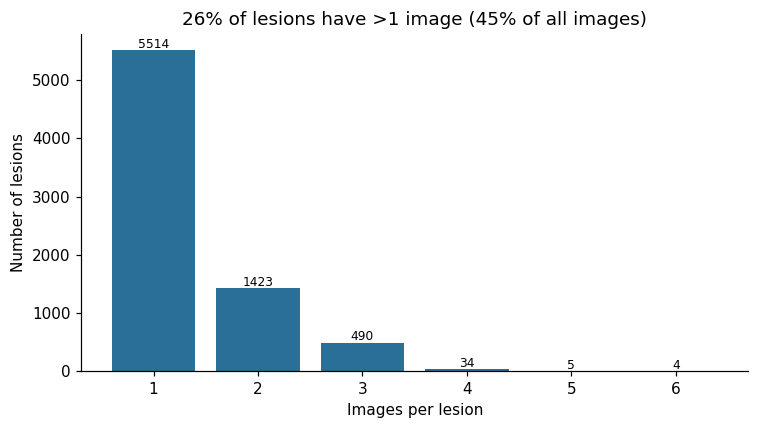

In [5]:
# D3. Images per lesion (why a lesion-level split is necessary)
per_lesion = meta.groupby("lesion_id").size()
multi_img_share = meta["lesion_id"].map(per_lesion).gt(1).mean()
vc = per_lesion.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(vc.index.astype(str), vc.values, color="#2a6f97")
for x, v in zip(vc.index.astype(str), vc.values):
    ax.text(x, v + 40, str(v), ha="center", fontsize=8)
ax.set_xlabel("Images per lesion"); ax.set_ylabel("Number of lesions")
ax.set_title(f"{per_lesion.gt(1).mean():.0%} of lesions have >1 image "
             f"({multi_img_share:.0%} of all images)")
plt.tight_layout(); SAVE(fig, "data_03_images_per_lesion"); plt.show()

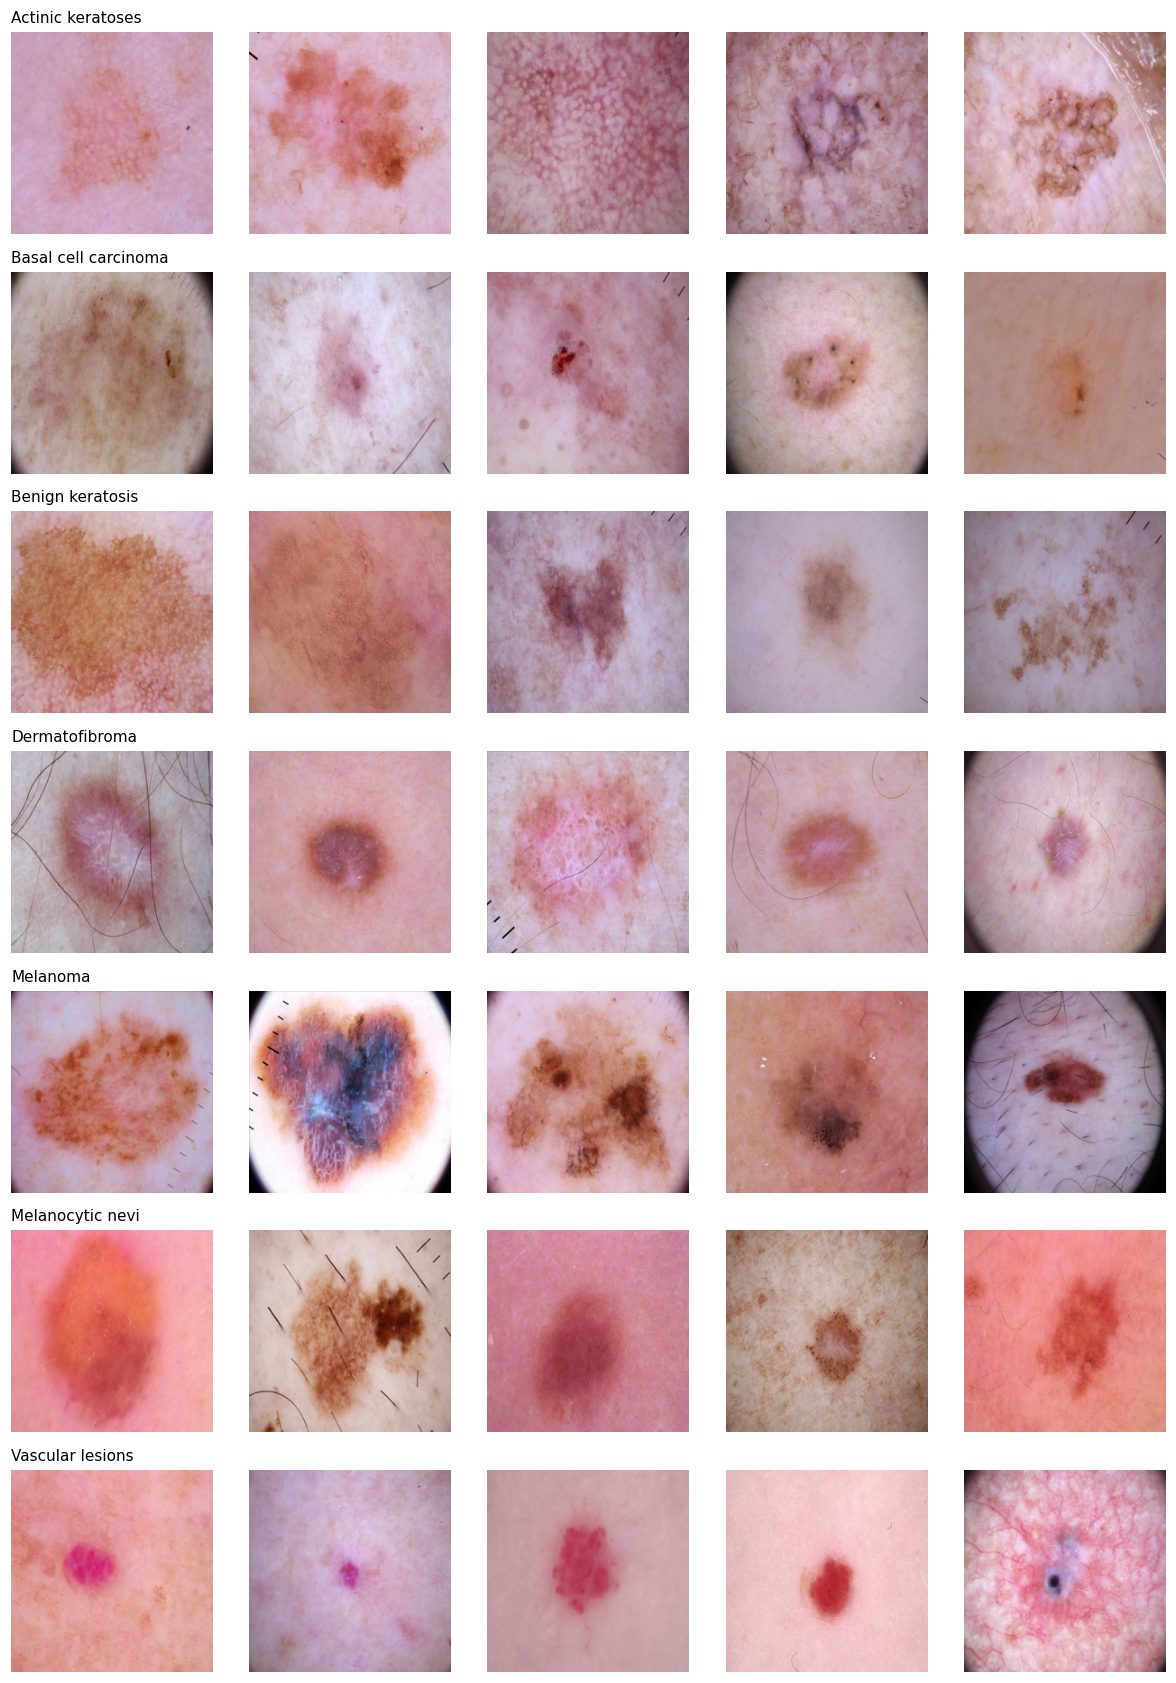

In [6]:
# D4. Example images per class
n_per = 5
fig, axes = plt.subplots(len(class_names), n_per, figsize=(2.2 * n_per, 2.2 * len(class_names)))
for r, c in enumerate(class_names):
    rows = meta[meta["dx"] == c].sample(n_per, random_state=SEED)
    for k, (_, rec) in enumerate(rows.iterrows()):
        img = Image.open(rec["path"]).convert("RGB").resize((224, 224))
        axes[r, k].imshow(img); axes[r, k].axis("off")
    axes[r, 0].set_title(FULL[c], loc="left", fontsize=10)
plt.tight_layout(); SAVE(fig, "data_04_example_images"); plt.show()

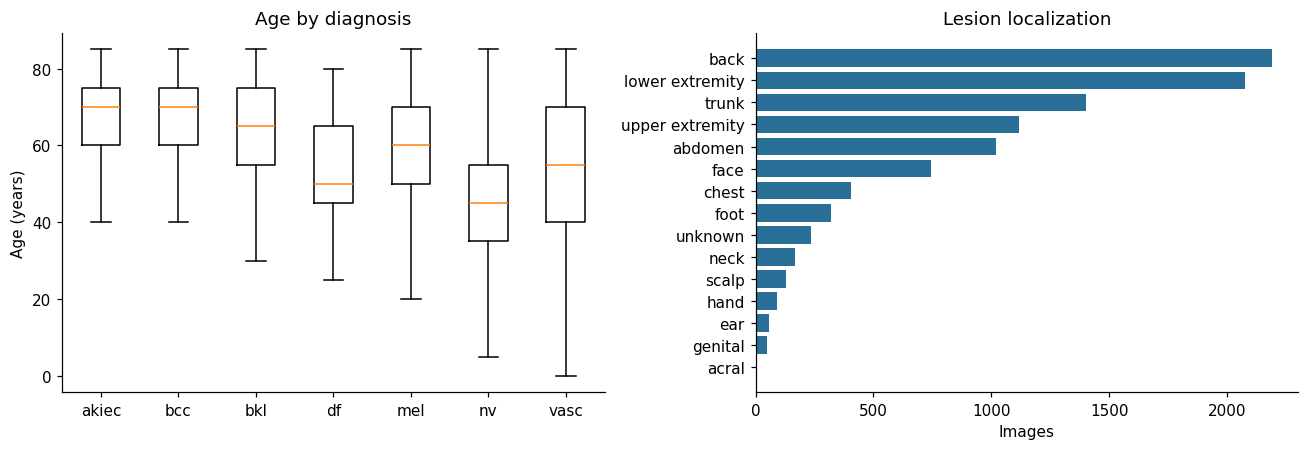

In [7]:
# D5. Metadata overview: age by class, lesion localization
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].boxplot([meta.loc[meta["dx"] == c, "age"].dropna() for c in class_names], showfliers=False)
ax[0].set_xticklabels(class_names); ax[0].set_ylabel("Age (years)"); ax[0].set_title("Age by diagnosis")
loc = meta["localization"].value_counts().sort_values()
ax[1].barh(loc.index, loc.values, color="#2a6f97"); ax[1].set_xlabel("Images")
ax[1].set_title("Lesion localization")
plt.tight_layout(); SAVE(fig, "data_05_metadata_overview"); plt.show()

In [8]:
# Predictions on the test set (loads the saved models, no retraining)
def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE)), tf.cast(label, tf.int32)


def predict_probs(model, frame):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].astype(str).to_numpy(),
                                             frame["label"].to_numpy(dtype=np.int32)))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
    p = model.predict(ds, verbose=0)
    return p / p.sum(axis=1, keepdims=True)


test = frames["test"]
y_true = test["label"].to_numpy(int)
model_files = {"CNN": "baseline_cnn.keras", "EfficientNetB0": "efficientnetb0.keras"}
probs = {}
for name, fname in model_files.items():
    cache = RESULTS_DIR / f"test_probs_{name}.npy"
    if cache.exists():
        probs[name] = np.load(cache)
    else:
        m = tf.keras.models.load_model(RESULTS_DIR / fname, compile=False)
        probs[name] = predict_probs(m, test)
        np.save(cache, probs[name])
    acc = (probs[name].argmax(1) == y_true).mean()
    print(f"{name}: test accuracy {acc:.3f}  (should match test_metrics.csv)")
preds = {k: v.argmax(1) for k, v in probs.items()}

CNN: test accuracy 0.607  (should match test_metrics.csv)
EfficientNetB0: test accuracy 0.664  (should match test_metrics.csv)


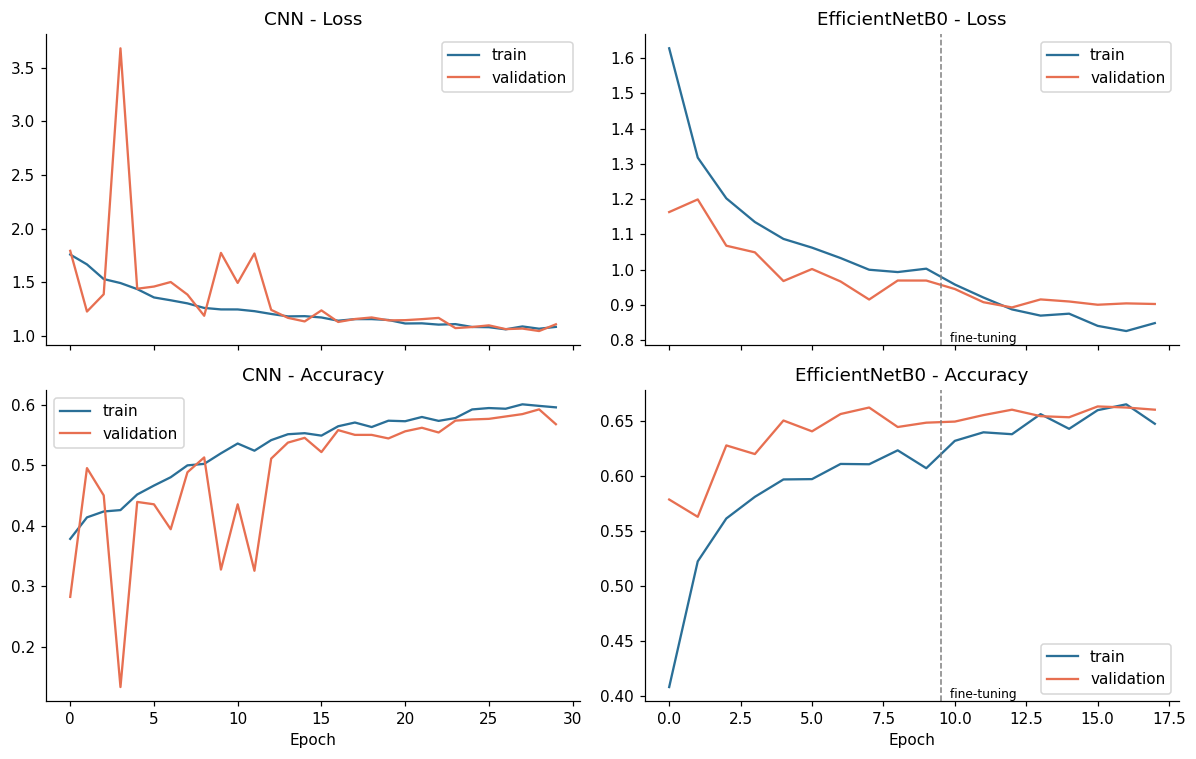

In [9]:
# Result figures
metrics = pd.read_csv(RESULTS_DIR / "test_metrics.csv").set_index("model")

# R1. Training curves (from the CSV logs written during training)
def read_log(n):
    p = RESULTS_DIR / f"{n}_training.csv"
    return pd.read_csv(p) if p.exists() else None


logs = {"CNN": [read_log("cnn")], "EfficientNetB0": [read_log("eff_head"), read_log("eff_fine")]}
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
for j, (mname, parts) in enumerate(logs.items()):
    parts = [p for p in parts if p is not None]
    if not parts:
        continue
    cat = pd.concat(parts, ignore_index=True)
    for i, (m, title) in enumerate([("loss", "Loss"), ("accuracy", "Accuracy")]):
        ax[i, j].plot(cat[m], label="train", color="#2a6f97")
        ax[i, j].plot(cat[f"val_{m}"], label="validation", color="#e76f51")
        if len(parts) == 2:
            ax[i, j].axvline(len(parts[0]) - 0.5, color="gray", ls="--", lw=1)
            ax[i, j].text(len(parts[0]) - 0.3, ax[i, j].get_ylim()[0], " fine-tuning", fontsize=8, va="bottom")
        ax[i, j].set_title(f"{mname} - {title}"); ax[i, j].legend()
    ax[1, j].set_xlabel("Epoch")
plt.tight_layout(); SAVE(fig, "result_01_training_curves"); plt.show()

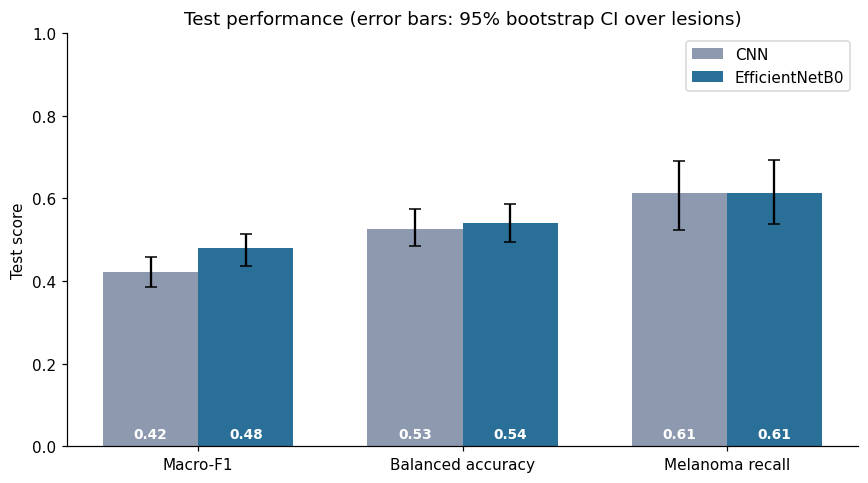

                accuracy  macro_f1  balanced_accuracy  melanoma_recall  \
model                                                                    
CNN                0.607     0.422              0.526            0.613   
EfficientNetB0     0.664     0.480              0.540            0.613   

                macro_auc_ovr  
model                          
CNN                     0.879  
EfficientNetB0          0.902  


In [10]:
# R2. Headline metrics with 95% lesion-level bootstrap CIs
show = [("macro_f1", "Macro-F1"), ("balanced_accuracy", "Balanced accuracy"), ("melanoma_recall", "Melanoma recall")]
fig, ax = plt.subplots(figsize=(8, 4.5))
w = 0.36
for k, mname in enumerate(["CNN", "EfficientNetB0"]):
    v = np.array([metrics.loc[mname, m] for m, _ in show])
    lo = np.array([metrics.loc[mname, f"{m}_ci_low"] for m, _ in show])
    hi = np.array([metrics.loc[mname, f"{m}_ci_high"] for m, _ in show])
    xs = np.arange(len(show)) + (k - 0.5) * w
    ax.bar(xs, v, w, yerr=[v - lo, hi - v], capsize=4, color=COL[mname], label=mname)
    for x, val in zip(xs, v):
        ax.text(x, 0.02, f"{val:.2f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_xticks(np.arange(len(show))); ax.set_xticklabels([n for _, n in show])
ax.set_ylim(0, 1); ax.set_ylabel("Test score"); ax.legend(loc="upper right")
ax.set_title("Test performance (error bars: 95% bootstrap CI over lesions)")
plt.tight_layout(); SAVE(fig, "result_02_headline_metrics_ci"); plt.show()
print(metrics[["accuracy", "macro_f1", "balanced_accuracy", "melanoma_recall", "macro_auc_ovr"]].round(3))

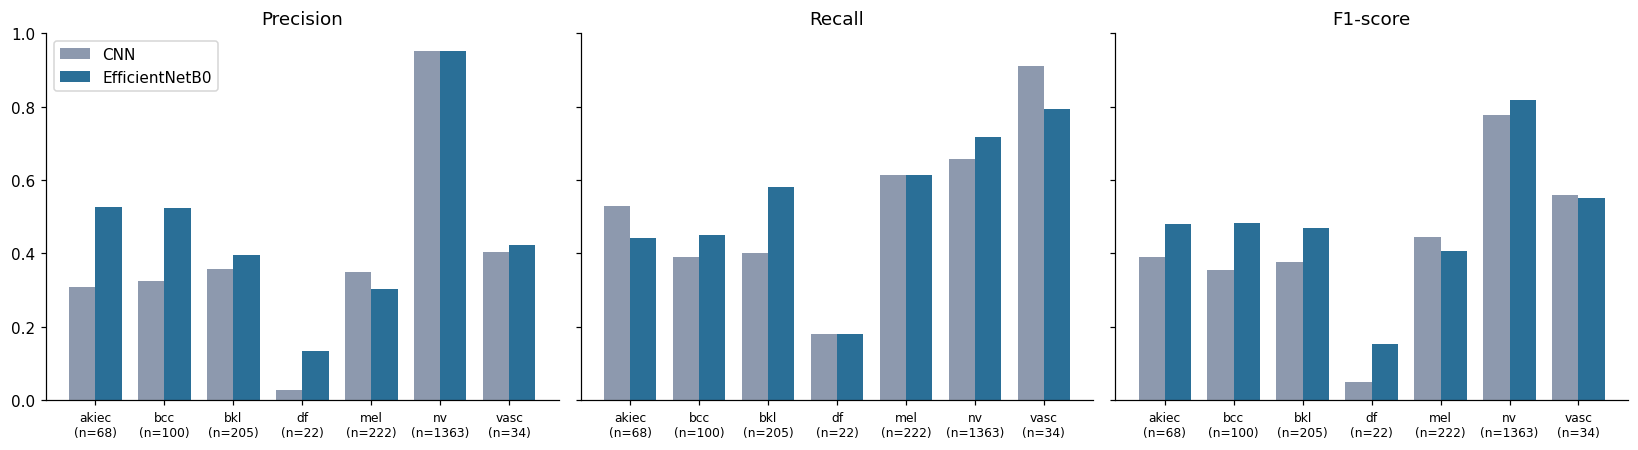

In [11]:
# R3. Per-class precision / recall / F1
support = np.bincount(y_true, minlength=len(class_names))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, (idx, title) in enumerate([(0, "Precision"), (1, "Recall"), (2, "F1-score")]):
    for k, mname in enumerate(["CNN", "EfficientNetB0"]):
        p, r, f, _ = precision_recall_fscore_support(y_true, preds[mname], labels=np.arange(len(class_names)),
                                                     zero_division=0)
        v = [p, r, f][idx]
        ax[j].bar(np.arange(len(class_names)) + (k - 0.5) * 0.38, v, 0.38, color=COL[mname],
                  label=mname if j == 0 else None)
    ax[j].set_xticks(np.arange(len(class_names)))
    ax[j].set_xticklabels([f"{c}\n(n={n})" for c, n in zip(class_names, support)], fontsize=8)
    ax[j].set_title(title); ax[j].set_ylim(0, 1)
ax[0].legend(); plt.tight_layout(); SAVE(fig, "result_03_per_class_metrics"); plt.show()

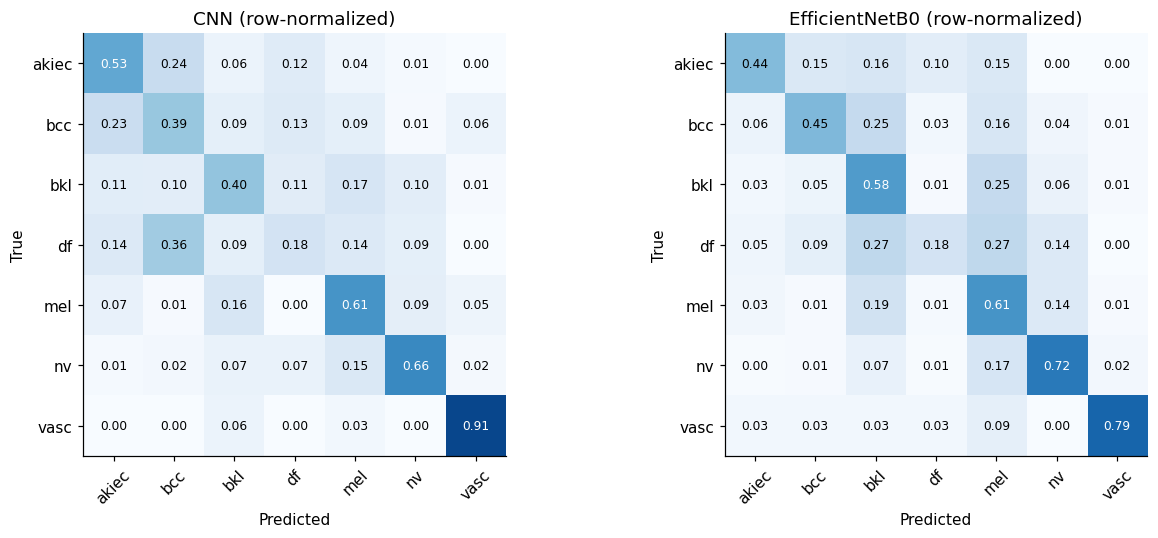

In [12]:
# R4. Confusion matrices side by side (row-normalized)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, mname in zip(ax, ["CNN", "EfficientNetB0"]):
    cm = confusion_matrix(y_true, preds[mname], labels=np.arange(len(class_names)), normalize="true")
    im = a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(len(class_names))); a.set_yticks(range(len(class_names)))
    a.set_xticklabels(class_names, rotation=45); a.set_yticklabels(class_names)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                   color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(f"{mname} (row-normalized)")
plt.tight_layout(); SAVE(fig, "result_04_confusion_matrices"); plt.show()

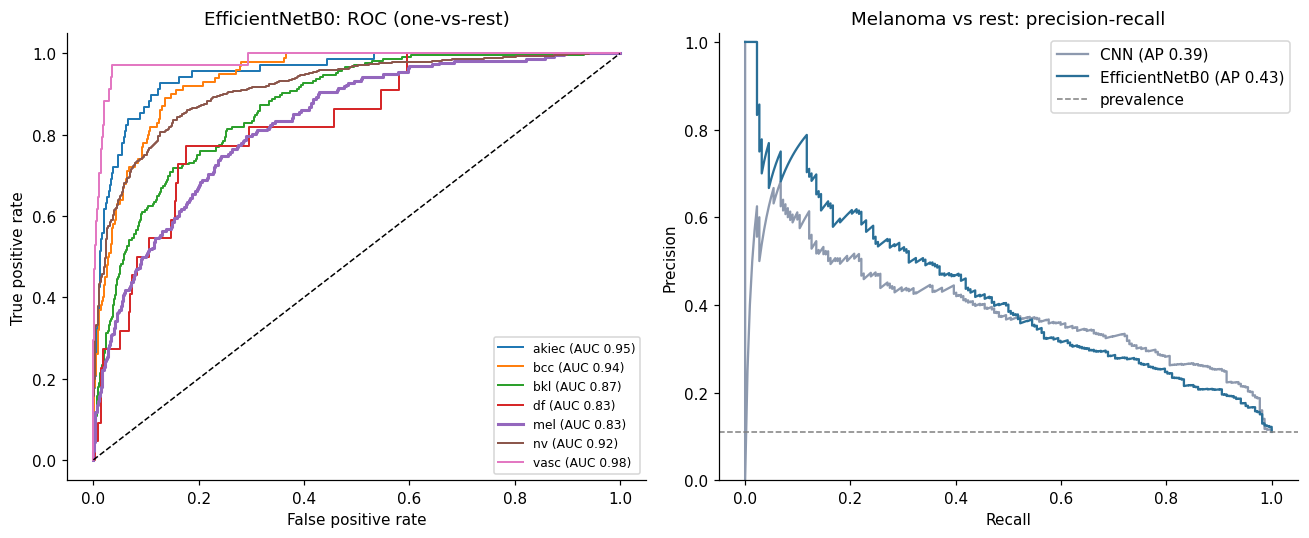

Figures saved to: /content/drive/MyDrive/HAM10000_results_final/figures


In [13]:
# R5. ROC curves (EfficientNet, one-vs-rest) and melanoma precision-recall curves
Y = label_binarize(y_true, classes=np.arange(len(class_names)))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for c, cname in enumerate(class_names):
    fpr, tpr, _ = roc_curve(Y[:, c], probs["EfficientNetB0"][:, c])
    ax[0].plot(fpr, tpr, lw=2 if c == MEL else 1.3, label=f"{cname} (AUC {auc(fpr, tpr):.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("EfficientNetB0: ROC (one-vs-rest)"); ax[0].legend(fontsize=8, loc="lower right")
for mname in ["CNN", "EfficientNetB0"]:
    pr, rc, _ = precision_recall_curve(Y[:, MEL], probs[mname][:, MEL])
    ax[1].plot(rc, pr, color=COL[mname], label=f"{mname} (AP {average_precision_score(Y[:, MEL], probs[mname][:, MEL]):.2f})")
ax[1].axhline(Y[:, MEL].mean(), color="gray", ls="--", lw=1, label="prevalence")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_ylim(0, 1.02)
ax[1].set_title("Melanoma vs rest: precision-recall"); ax[1].legend()
plt.tight_layout(); SAVE(fig, "result_05_roc_and_melanoma_pr"); plt.show()
print("Figures saved to:", FIG_DIR)